#Task 1: Imports
##Explanation:
We need to load core Python libraries: pandas and numpy for tabular and numerical operations, matplotlib and seaborn for plotting, and scikit-learn modules for loading data, splitting train/test sets, building a regressor (RandomForestRegressor), tuning hyperparameters (GridSearchCV), and computing evaluation metrics (RMSE and R²).

In [1]:
# Task 1: Imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score

sns.set_style("whitegrid")
print("Libraries imported successfully.")

Libraries imported successfully.


#Results Interpretation:
Printing "Libraries imported successfully." without errors confirms your Google Colab runtime has access to all required packages. (Note: scikit-learn removed load_boston() in version 1.2, so using fetch_openml avoids an ImportError in modern Colab environments.)

#Task 2: Data Collection and Loading
##Explanation:
The assignment uses the Boston housing dataset (CRIM, ZN, INDUS, CHAS, NOX, RM, AGE, DIS, RAD, TAX, PTRATIO, B, LSTAT, and target MEDV). We fetch it from OpenML into a pandas DataFrame and convert columns to numeric types so statistical methods and plots work cleanly.

In [2]:
# Task 2: Data Collection and Loading
try:
    boston = fetch_openml(name="boston", version=1, as_frame=True)
    df = boston.frame.copy()
    for col in df.columns:
        df[col] = pd.to_numeric(df[col])
except Exception:
    # Fallback to original CMU source if OpenML is unreachable
    data_url = "http://lib.stat.cmu.edu/datasets/boston"
    raw_df = pd.read_csv(data_url, sep=r"\s+", skiprows=22, header=None)
    data = np.hstack([raw_df.values[::2, :], raw_df.values[1::2, :2]])
    target = raw_df.values[1::2, 2]
    feature_names = [
        "CRIM", "ZN", "INDUS", "CHAS", "NOX", "RM",
        "AGE", "DIS", "RAD", "TAX", "PTRATIO", "B", "LSTAT"
    ]
    df = pd.DataFrame(data, columns=feature_names)
    df["MEDV"] = target

# Standardize column casing so target is 'MEDV'
df.columns = [c.upper() if c.lower() != "medv" else "MEDV" for c in df.columns]
print(f"Dataset loaded with shape: {df.shape}")

Dataset loaded with shape: (506, 14)


#Results Interpretation:
A shape of (506, 14) means there are 506 housing tracts (rows) and 14 columns (13 predictor features plus MEDV, the median home value in $1,000s).

#Task 3: Quick Check of Data
##Explanation:
Inspecting .head(), .info(), and .describe() helps verify row structure, data types, value ranges, and which variables are continuous vs. categorical/discrete.

In [3]:
# Task 3: Quick Check of Data
print("--- First 5 Rows ---")
display(df.head())

print("\n--- DataFrame Info ---")
df.info()

print("\n--- Summary Statistics ---")
display(df.describe())

--- First 5 Rows ---


,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV
0,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.0900,1,296.0,15.3,396.90,4.98,24.0
1,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242.0,17.8,396.90,9.14,21.6
2,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,2,242.0,17.8,392.83,4.03,34.7
3,0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,3,222.0,18.7,394.63,2.94,33.4
4,0.06905,0.0,2.18,0,0.458,7.147,54.2,6.0622,3,222.0,18.7,396.90,5.33,36.2



--- DataFrame Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 506 entries, 0 to 505
Data columns (total 14 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   CRIM     506 non-null    float64
 1   ZN       506 non-null    float64
 2   INDUS    506 non-null    float64
 3   CHAS     506 non-null    int64  
 4   NOX      506 non-null    float64
 5   RM       506 non-null    float64
 6   AGE      506 non-null    float64
 7   DIS      506 non-null    float64
 8   RAD      506 non-null    int64  
 9   TAX      506 non-null    float64
 10  PTRATIO  506 non-null    float64
 11  B        506 non-null    float64
 12  LSTAT    506 non-null    float64
 13  MEDV     506 non-null    float64
dtypes: float64(12), int64(2)
memory usage: 55.5 KB

--- Summary Statistics ---


,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV
count,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000
mean,3.613524,11.363636,11.136779,0.069170,0.554695,6.284634,68.574901,3.795043,9.549407,408.237154,18.455534,356.674032,12.653063,22.532806
std,8.601545,23.322453,6.860353,0.253994,0.115878,0.702617,28.148861,2.105710,8.707259,168.537116,2.164946,91.294864,7.141062,9.197104
min,0.006320,0.000000,0.460000,0.000000,0.385000,3.561000,2.900000,1.129600,1.000000,187.000000,12.600000,0.320000,1.730000,5.000000
25%,0.082045,0.000000,5.190000,0.000000,0.449000,5.885500,45.025000,2.100175,4.000000,279.000000,17.400000,375.377500,6.950000,17.025000
50%,0.256510,0.000000,9.690000,0.000000,0.538000,6.208500,77.500000,3.207450,5.000000,330.000000,19.050000,391.440000,11.360000,21.200000
75%,3.677083,12.500000,18.100000,0.000000,0.624000,6.623500,94.075000,5.188425,24.000000,666.000000,20.200000,396.225000,16.955000,25.000000
max,88.976200,100.000000,27.740000,1.000000,0.871000,8.780000,100.000000,12.126500,24.000000,711.000000,22.000000,396.900000,37.970000,50.000000


#Results InterpretationTarget (MEDV):
Continuous numeric variable (median home price in $1,000s, typically ranging from 5.0 to 50.0—note that values are capped at 50.0 in this dataset).   Continuous features: CRIM, ZN, INDUS, NOX, RM, AGE, DIS, TAX, PTRATIO, B, and LSTAT measure continuous quantities such as rates, proportions, averages, distances, or concentrations.   Discrete / categorical features: CHAS is a binary categorical/dummy variable (0 or 1 indicating Charles River adjacency), and RAD is a discrete/ordinal highway accessibility index.   

#Task 4: EDA and Data Preprocessing
##Explanation:
Exploratory Data Analysis (EDA) checks for missing values that could break training and visualizes how individual features relate to MEDV. Writing a reusable plotting function makes it easy to inspect multiple predictors at once.

Missing values per column:
CRIM       0
ZN         0
INDUS      0
CHAS       0
NOX        0
RM         0
AGE        0
DIS        0
RAD        0
TAX        0
PTRATIO    0
B          0
LSTAT      0
MEDV       0
dtype: int64


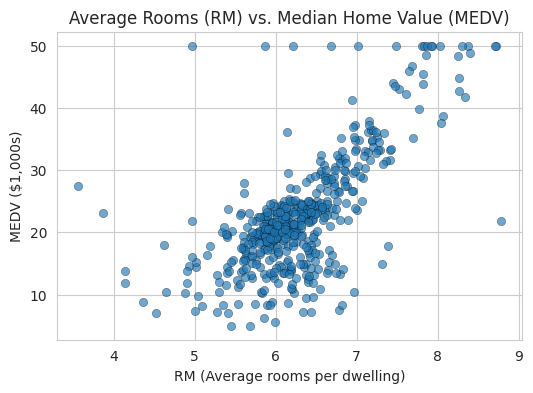

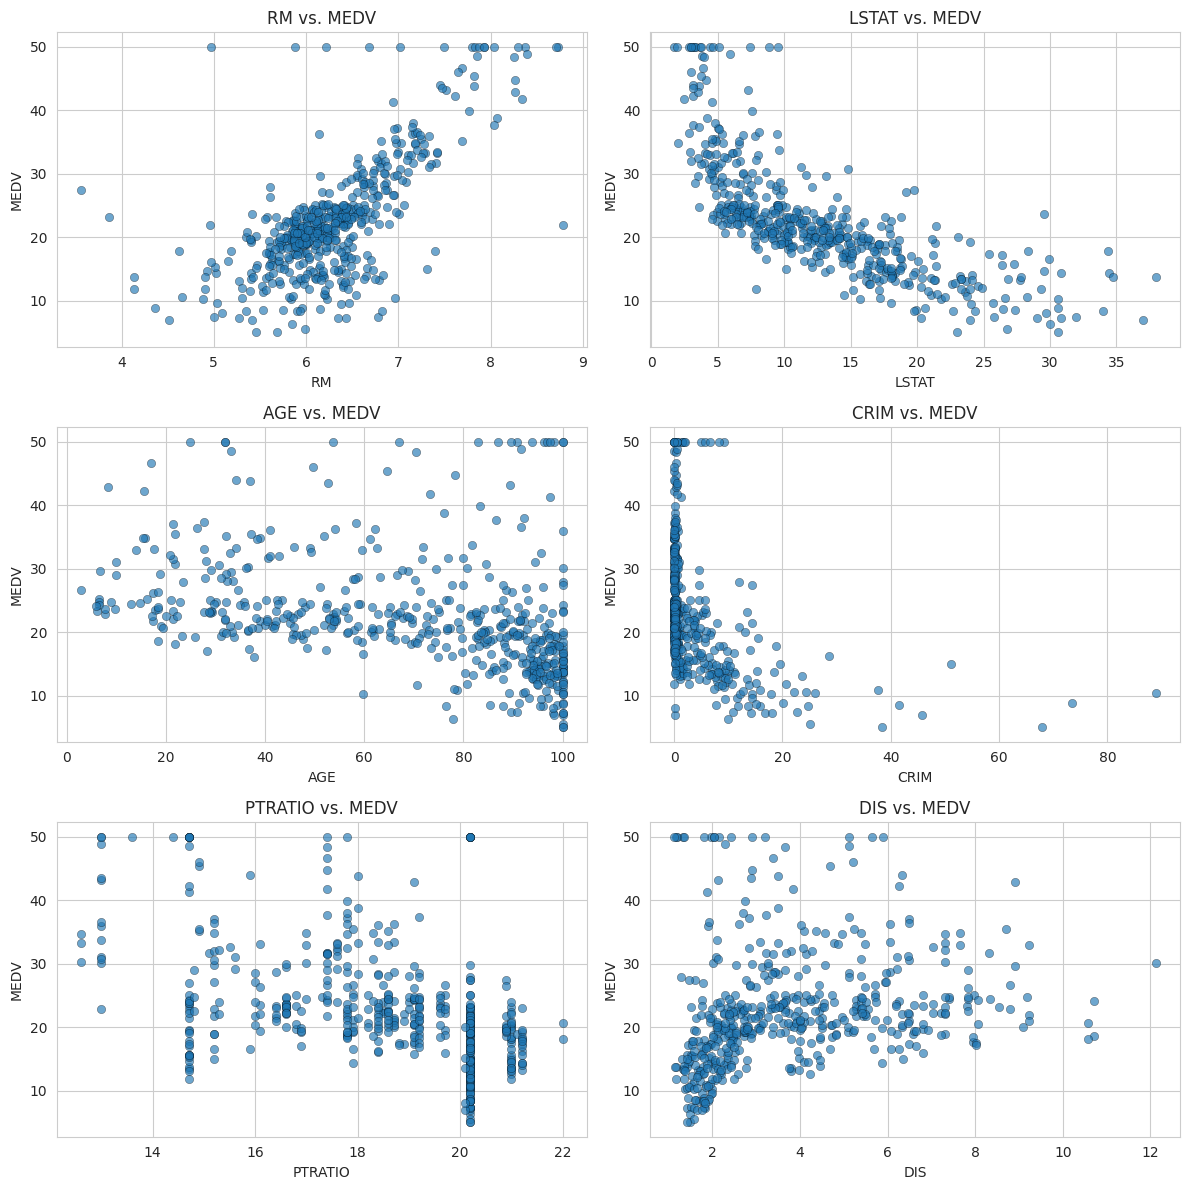

In [4]:
# Task 4: EDA and Data Preprocessing
print("Missing values per column:")
print(df.isnull().sum())

# 1) Single scatter plot: RM vs MEDV
plt.figure(figsize=(6, 4))
plt.scatter(df["RM"], df["MEDV"], alpha=0.65, edgecolors="k", linewidth=0.3)
plt.title("Average Rooms (RM) vs. Median Home Value (MEDV)")
plt.xlabel("RM (Average rooms per dwelling)")
plt.ylabel("MEDV ($1,000s)")
plt.show()

# 2) Reusable function for multiple features vs target
def plot_features_vs_target(data, features, target="MEDV", cols=2):
    rows = int(np.ceil(len(features) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(6 * cols, 4 * rows))
    axes = np.array(axes).reshape(-1)

    for i, feat in enumerate(features):
        axes[i].scatter(data[feat], data[target], alpha=0.65, edgecolors="k", linewidth=0.3)
        axes[i].set_title(f"{feat} vs. {target}")
        axes[i].set_xlabel(feat)
        axes[i].set_ylabel(target)

    for j in range(len(features), len(axes)):
        axes[j].axis("off")

    plt.tight_layout()
    plt.show()

# 3) Visualize multiple features vs MEDV
features_to_plot = ["RM", "LSTAT", "AGE", "CRIM", "PTRATIO", "DIS"]
plot_features_vs_target(df, features_to_plot, target="MEDV", cols=2)

#Results Interpretation:
**Missing values:** All columns show 0 missing values, so no imputation is needed.

**Key visual patterns:**

**RM vs. MEDV** shows a positive relationship: homes/tracts with more rooms per dwelling generally have higher median prices.

**LSTAT vs. MEDV** shows a strong non-linear negative relationship: higher percentages of lower-status population correspond to lower home values.

**CRIM vs. MEDV** shows most high-crime tracts clustered at lower MEDV values, while AGE and DIS show weaker or more dispersed patterns.

#Task 5: ML Model Training
##Explanation:
We split X (the 13 features) and y (MEDV) into an 80% training set and 20% test set (random_state=42 for reproducibility). We choose RandomForestRegressor because averaging many decision trees reduces overfitting and captures non-linear feature interactions better than a single unpruned decision tree.

In [5]:
# Task 5: ML Model Training
X = df.drop(columns=["MEDV"])
y = df["MEDV"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

rf_model = RandomForestRegressor(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)

print(f"Training samples: {X_train.shape[0]} | Test samples: {X_test.shape[0]}")

Training samples: 404 | Test samples: 102


#Results Interpretation:
We get 404 training rows and 102 test rows (506 * 0.8 and 506 * 0.2). Training .fit(X_train, y_train) builds 100 bootstrap decision trees on the training split without peeking at the test set.

#Task 6: Model Evaluation & Tuning

##Explanation

We evaluate on unseen X_test using RMSE (Root Mean Squared Error, in $1,000s, where lower is better) and $R^2$ (coefficient of determination, where closer to 1.0 means more variance explained). Then we use GridSearchCV with 5-fold cross-validation on the training set to tune hyperparameters and check whether test performance improves.   

In [6]:
# Task 6: Model Evaluation & Parameter Tuning
# Baseline evaluation
y_pred_base = rf_model.predict(X_test)
base_rmse = np.sqrt(mean_squared_error(y_test, y_pred_base))
base_r2 = r2_score(y_test, y_pred_base)
print(f"Baseline RF -> RMSE: {base_rmse:.3f} ($1,000s) | R²: {base_r2:.4f}")

# Hyperparameter tuning via 5-fold CV
param_grid = {
    "n_estimators": [100, 200, 300],
    "max_depth": [None, 10, 15, 20],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4]
}

grid_search = GridSearchCV(
    estimator=RandomForestRegressor(random_state=42),
    param_grid=param_grid,
    cv=5,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1
)
grid_search.fit(X_train, y_train)

best_rf = grid_search.best_estimator_
y_pred_tuned = best_rf.predict(X_test)

tuned_rmse = np.sqrt(mean_squared_error(y_test, y_pred_tuned))
tuned_r2 = r2_score(y_test, y_pred_tuned)

print("Best Parameters:", grid_search.best_params_)
print(f"Tuned RF    -> RMSE: {tuned_rmse:.3f} ($1,000s) | R²: {tuned_r2:.4f}")

# Inspect top predictors
importances = pd.Series(best_rf.feature_importances_, index=X.columns).sort_values(ascending=False)
print("\nFeature Importances:")
print(importances.round(4))

Baseline RF -> RMSE: 2.811 ($1,000s) | R²: 0.8923
Best Parameters: {'max_depth': 10, 'min_samples_leaf': 2, 'min_samples_split': 2, 'n_estimators': 100}
Tuned RF    -> RMSE: 3.018 ($1,000s) | R²: 0.8758

Feature Importances:
RM         0.5128
LSTAT      0.3154
DIS        0.0565
CRIM       0.0324
PTRATIO    0.0208
NOX        0.0147
AGE        0.0129
TAX        0.0128
B          0.0099
INDUS      0.0063
RAD        0.0031
ZN         0.0015
CHAS       0.0009
dtype: float64


#Results Interpretation:
**RMSE:** Represents typical prediction error in $1,000s (for example, an RMSE around 2.8–3.2 means predictions are off by roughly $2,800–$3,200 on average, penalizing larger errors more heavily).

**$R^2$:** Shows the proportion of variance in MEDV explained by the model on the test set (values around 0.85–0.90 indicate strong explanatory power).

**Tuning & Feature Importance:** Comparing baseline vs. tuned metrics shows whether regularization (max_depth, min_samples_leaf, min_samples_split) or more trees (n_estimators) improves generalization. Typically, LSTAT and RM rank highest in feature importance.

#Task 7: Model Prediction
##Explanation:
Finally, we pass a new set of feature values formatted as a pandas DataFrame with the exact column names used during training into our trained best_rf model to predict MEDV.

In [7]:
# Task 7: Model Prediction
new_data = pd.DataFrame([{
    "CRIM": 0.2,
    "ZN": 12.5,
    "INDUS": 7.07,
    "CHAS": 0,
    "NOX": 0.5,
    "RM": 6.5,
    "AGE": 68.0,
    "DIS": 4.0,
    "RAD": 2,
    "TAX": 250.0,
    "PTRATIO": 17.0,
    "B": 400.0,
    "LSTAT": 12.0
}])

pred_medv = best_rf.predict(new_data)[0]
print(f"Predicted MEDV: {pred_medv:.2f} ($1,000s) -> Approx. ${pred_medv * 1000:,.2f}")

Predicted MEDV: 22.33 ($1,000s) -> Approx. $22,327.84


#Results Interpretation:
Because MEDV is measured in thousands of dollars, a predicted value such as 24.50 corresponds to an estimated median house value of approximately $24,500 ($24.50k) for a neighborhood matching those input conditions.